# Volumen de urgencias en Sonora

¿Cómo se distribuyen las atenciones reportadas por mes, establecimiento y municipio? El libro de Servicios de Salud de Sonora reúne registros agregados de 2018–2022. Cada fila aporta el conteo de la columna **Total_Urgencias**. El periodo y el alcance corresponden a lo que reporta el archivo. Para estudiar tiempos de espera se necesitarían las horas de llegada y primera atención.

[Ingesta y diccionario de urgencias](../docs/workflow.md)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")

inicio = Path.cwd().resolve()
raiz = next(ruta for ruta in (inicio, *inicio.parents) if (ruta / "config/fuentes_health.yaml").is_file())
archivo = raiz / "data/raw/sonora_urgencias_2018_2022.xlsx"
columnas = {
    "CLUES": "clues", "Nombre_Establecimiento": "establecimiento",
    "Mun_Clave": "cve_municipio", "Mun_Nombre": "municipio",
    "Año": "anio", "Mes": "mes", "CIE10_Cve": "cie10", "Total_Urgencias": "urgencias"
}
crudo = pd.read_excel(archivo, sheet_name="ATENCIONES URGENCIAS 2018-2022",
                      usecols=list(columnas), dtype={"CLUES": "string", "Mun_Clave": "string",
                                                     "CIE10_Cve": "string"}).rename(columns=columnas)
for campo in ("clues", "establecimiento", "municipio", "cie10"):
    crudo[campo] = crudo[campo].astype("string").str.strip().str.upper()
for campo in ("anio", "mes", "urgencias"):
    crudo[campo] = pd.to_numeric(crudo[campo], errors="coerce")

conteo_valido = crudo["urgencias"].ge(0) & crudo["urgencias"].mod(1).eq(0)
periodo_valido = crudo["anio"].between(2018, 2022) & crudo["mes"].between(1, 12)
periodo_valido &= crudo["anio"].mod(1).eq(0) & crudo["mes"].mod(1).eq(0)
validas = crudo.loc[conteo_valido & periodo_valido].copy()
validas["urgencias"] = validas["urgencias"].astype("int64")
validas["periodo"] = pd.to_datetime(
    {"year": validas["anio"], "month": validas["mes"], "day": 1}
)
validas["clues"] = validas["clues"].where(validas["clues"].str.fullmatch(r"[A-Z]{5}[0-9]{6}").fillna(False))

auditoria = pd.Series({
    "Filas originales": len(crudo),
    "Filas con conteo inválido": int((~conteo_valido).sum()),
    "Filas con periodo inválido": int((~periodo_valido).sum()),
    "Filas incluidas": len(validas),
    "Urgencias incluidas": int(validas["urgencias"].sum()),
    "Urgencias sin CLUES válido": int(validas.loc[validas["clues"].isna(), "urgencias"].sum()),
    "CLUES válidas distintas": validas["clues"].nunique(),
}, name="valor")
display(auditoria.to_frame())

,valor
Filas originales,622784
Filas con conteo inválido,0
Filas con periodo inválido,0
Filas incluidas,622784
Urgencias incluidas,845944
Urgencias sin CLUES válido,0
CLUES válidas distintas,21


## Cobertura temporal

Los meses se consideran observados cuando tienen al menos una fila válida. Los huecos se mantienen en la serie. La columna de meses reportados indica cuándo comparar sumas anuales exige ajustar el periodo.

,urgencias_reportadas,meses_reportados
2018,255721,12
2019,247118,12
2020,158485,12
2021,126885,12
2022,57735,6


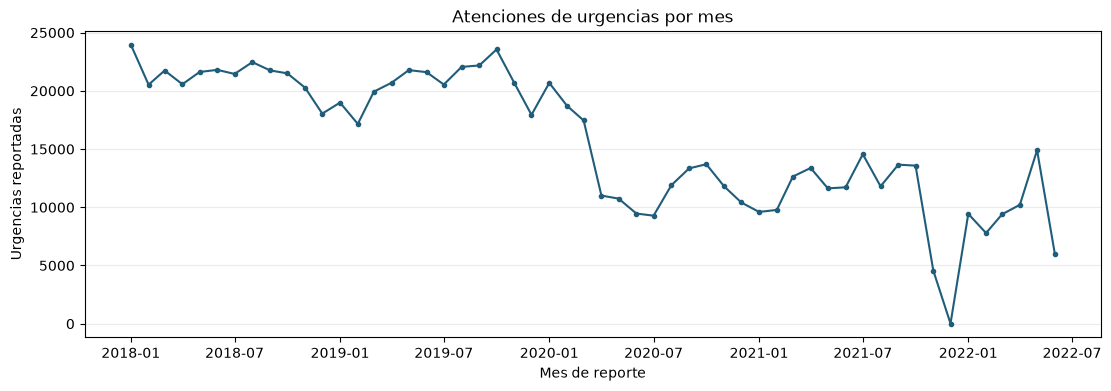

In [2]:
mensual = validas.groupby("periodo")["urgencias"].sum().sort_index()
calendario = pd.date_range(mensual.index.min(), mensual.index.max(), freq="MS")
mensual = mensual.reindex(calendario).rename("urgencias")
anual = mensual.groupby(mensual.index.year).agg(
    urgencias_reportadas=lambda serie: serie.sum(min_count=1), meses_reportados="count"
)
assert anual["urgencias_reportadas"].sum() == validas["urgencias"].sum()
display(anual)

figura, eje = plt.subplots(figsize=(11, 3.8), layout="constrained")
eje.plot(mensual.index, mensual, color="#205d7b", marker="o", markersize=3)
eje.set(title="Atenciones de urgencias por mes", ylabel="Urgencias reportadas", xlabel="Mes de reporte")
eje.grid(axis="y", alpha=.25)
plt.show()

## Establecimientos, municipios y diagnósticos

CLUES identifica el establecimiento en el ranking. La columna de municipio conserva el nombre reportado en el libro. Los porcentajes de concentración usan el total de atenciones incluidas del archivo.

,urgencias,establecimientos,meses_reportados
municipio,,,
HERMOSILLO,240936,2,51
CAJEME,123228,1,53
GUAYMAS,72463,1,53
HUATABAMPO,51515,1,53
CABORCA,47503,2,53
NOGALES,44480,1,53
CANANEA,43070,2,53
AGUA PRIETA,36578,1,53
NAVOJOA,36543,1,53


,establecimiento,urgencias,meses_reportados
clues,,,
SRSSA001105,HOSPITAL INFANTIL DEL ESTADO DE SONORA,132335,45
SRSSA000562,HOSPITAL GENERAL CD. OBREGÓN,123228,53
SRSSA001110,HOSPITAL GENERAL DEL ESTADO DR. ERNESTO RAMOS ...,108601,50
SRSSA001011,HOSPITAL GENERAL GUAYMAS,72463,53
SRSSA018313,HOSPITAL GENERAL DEL BAJO RIO MAYO,51515,53
SRSSA006261,HOSPITAL GENERAL DE CABORCA,45905,52
SRSSA001851,HOSPITAL GENERAL NOGALES,44480,53
SRSSA017671,HOSPITAL GENERAL DE AGUA PRIETA,36578,53
SRSSA001670,HOSPITAL GENERAL NAVOJOA,36543,53


,urgencias
cie10,
Z349,77040
J00X,24023
R104,23934
I10X,22599
A099,20914
N390,19488
R69X,17101
J029,13022
J068,11790


Los **tres establecimientos con más registros** reúnen el **43.0%** de las **845,944 urgencias** analizadas.

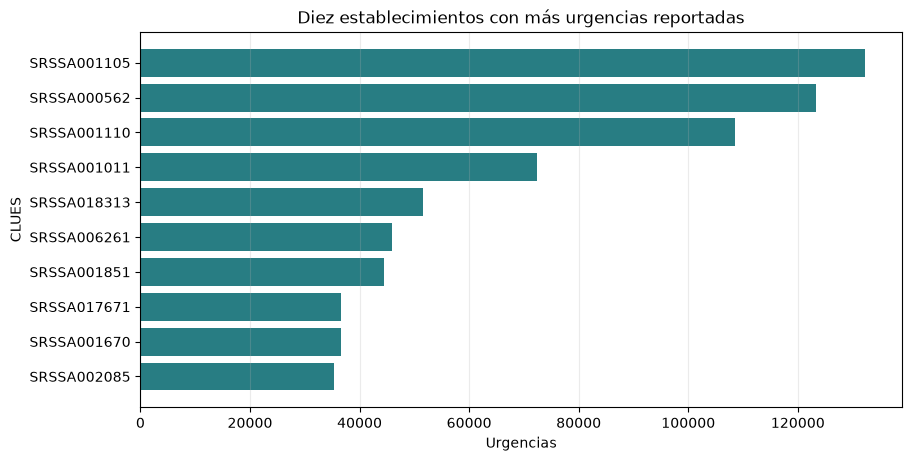

In [3]:
def nombre_frecuente(serie):
    presentes = serie.dropna()
    return presentes.value_counts().index[0] if not presentes.empty else pd.NA

unidades = (
    validas.dropna(subset=["clues"]).groupby("clues", observed=True)
    .agg(establecimiento=("establecimiento", nombre_frecuente), urgencias=("urgencias", "sum"),
         meses_reportados=("periodo", "nunique"))
    .sort_values("urgencias", ascending=False)
)
municipios = validas.groupby(validas["municipio"].fillna("SIN DATO"), observed=True).agg(
    urgencias=("urgencias", "sum"), establecimientos=("clues", "nunique"),
    meses_reportados=("periodo", "nunique")
).sort_values("urgencias", ascending=False)
diagnosticos = validas.groupby(validas["cie10"].fillna("SIN DATO"), observed=True)["urgencias"].sum().nlargest(12)

display(municipios)
display(unidades.head(10))
display(diagnosticos.rename("urgencias").to_frame())

totales = validas["urgencias"].sum()
concentracion = unidades["urgencias"].head(3).sum() / totales
display(Markdown(
    f"Los **tres establecimientos con más registros** reúnen el **{concentracion:.1%}** "
    f"de las **{totales:,} urgencias** analizadas."
))
figura, eje = plt.subplots(figsize=(9, 4.5), layout="constrained")
principales = unidades.head(10).iloc[::-1]
eje.barh(principales.index, principales["urgencias"], color="#287d83")
eje.set(title="Diez establecimientos con más urgencias reportadas", xlabel="Urgencias", ylabel="CLUES")
eje.grid(axis="x", alpha=.25)
plt.show()

## Cobertura de los destinos hospitalarios del proyecto

El cruce identifica qué destinos hospitalarios de la tabla de accesibilidad aparecen en el archivo de urgencias. El volumen corresponde a las atenciones reportadas entre 2018 y 2022. La población asignada proviene del ITER 2020 y de los destinos calculados por el proyecto.

In [4]:
ruta_acceso = raiz / "data/processed/accesibilidad_localidades.parquet"
if ruta_acceso.is_file():
    asignaciones = pd.read_parquet(ruta_acceso, columns=[
        "nearest_secondary_clues", "locality_id", "population", "secondary_method"
    ])
    print("Métodos de traslado:", asignaciones["secondary_method"].value_counts().to_dict())
    asignaciones["clues"] = asignaciones["nearest_secondary_clues"].astype("string").str.strip().str.upper()
    destinos = asignaciones.dropna(subset=["clues"]).groupby("clues").agg(
        localidades=("locality_id", "size"), poblacion_asignada=("population", "sum")
    )
    cruce = destinos.join(unidades, how="left")
    cubiertos = cruce["urgencias"].notna()
    display(pd.Series({
        "Destinos hospitalarios del proyecto": len(cruce),
        "Destinos con urgencias reportadas": int(cubiertos.sum()),
        "Población asignada a esos destinos": int(cruce.loc[cubiertos, "poblacion_asignada"].sum()),
    }, name="valor").to_frame())
    display(cruce.loc[cubiertos].nlargest(12, "poblacion_asignada"))
else:
    display(Markdown("El cruce de destinos queda pendiente hasta disponer de la tabla de accesibilidad."))

Métodos de traslado: {'estimado': 7297}


,valor
Destinos hospitalarios del proyecto,66
Destinos con urgencias reportadas,0
Población asignada a esos destinos,0


,localidades,poblacion_asignada,establecimiento,urgencias,meses_reportados
clues,,,,,


In [5]:
salida = raiz / "data/processed/urgencias_mensuales.parquet"
salida.parent.mkdir(parents=True, exist_ok=True)
resumen_tablero = (
    validas.groupby(["periodo", "municipio", "clues"], dropna=False)["urgencias"]
    .sum().reset_index()
    .merge(unidades[["establecimiento"]], left_on="clues", right_index=True, how="left", validate="many_to_one")
)
assert resumen_tablero["urgencias"].sum() == validas["urgencias"].sum()
resumen_tablero.to_parquet(salida, index=False)